In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
# Set paths and configuration

# ============================================
# Cell 2: Paths and configuration
# ============================================

PROJECT_DIR = Path.cwd().parent

FACE_DATASET_DIR = PROJECT_DIR / "face_dataset"

TRAIN_DIR = FACE_DATASET_DIR / "train"
VAL_DIR = FACE_DATASET_DIR / "validation"
TEST_DIR = FACE_DATASET_DIR / "test"

IMG_SIZE = 224
BATCH_SIZE = 16
NUM_CLASSES = 2

print("Project directory:", PROJECT_DIR)
print("Face dataset:", FACE_DATASET_DIR)

print()
print("Train exists:", TRAIN_DIR.exists())
print("Validation exists:", VAL_DIR.exists())
print("Test exists:", TEST_DIR.exists())

Project directory: d:\deepfake
Face dataset: d:\deepfake\face_dataset

Train exists: True
Validation exists: True
Test exists: True


In [3]:
# Create image transformations

# ============================================
# Cell 3: Image transformations
# ============================================

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(10),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


print("Training transformations created.")
print("Validation/Test transformations created.")

Training transformations created.
Validation/Test transformations created.


In [4]:
# ============================================
# Cell 4: Create datasets
# ============================================

train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    root=VAL_DIR,
    transform=val_test_transform
)

test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=val_test_transform
)


print("Datasets created successfully.")
print()

print("Class mapping:", train_dataset.class_to_idx)

print()
print("Training images   :", len(train_dataset))
print("Validation images :", len(val_dataset))
print("Test images       :", len(test_dataset))

Datasets created successfully.

Class mapping: {'fake': 0, 'real': 1}

Training images   : 1232
Validation images : 266
Test images       : 270


In [5]:
# ============================================
# Cell 5: Create DataLoaders
# ============================================

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


print("DataLoaders created successfully.")
print()

print("Training batches   :", len(train_loader))
print("Validation batches :", len(val_loader))
print("Test batches       :", len(test_loader))

DataLoaders created successfully.

Training batches   : 77
Validation batches : 17
Test batches       : 17


In [6]:
# ============================================
# Cell 6: Verify one batch
# ============================================

images, labels = next(iter(train_loader))

print("Image batch shape :", images.shape)
print("Label batch shape :", labels.shape)

print()
print("First 10 labels:", labels[:10].tolist())

print()
print("Image data type :", images.dtype)
print("Image min value :", images.min().item())
print("Image max value :", images.max().item())

Image batch shape : torch.Size([16, 3, 224, 224])
Label batch shape : torch.Size([16])

First 10 labels: [1, 1, 0, 0, 0, 0, 1, 1, 1, 0]

Image data type : torch.float32
Image min value : -2.1179039478302
Image max value : 2.640000104904175


In [7]:
# ============================================
# Cell 7: Load EfficientNet-B0
# ============================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# Load pretrained EfficientNet-B0
weights = models.EfficientNet_B0_Weights.DEFAULT

model = models.efficientnet_b0(
    weights=weights
)


# Replace original classifier
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    NUM_CLASSES
)


# Move model to device
model = model.to(device)


print()
print("EfficientNet-B0 loaded successfully.")
print()
print("Final classifier:")
print(model.classifier[1])

Device: cpu

EfficientNet-B0 loaded successfully.

Final classifier:
Linear(in_features=1280, out_features=2, bias=True)


In [8]:
# ============================================
# Cell 8: Freeze feature extractor
# ============================================

# Freeze all EfficientNet parameters
for param in model.features.parameters():
    param.requires_grad = False


# Keep the classifier trainable
for param in model.classifier.parameters():
    param.requires_grad = True


# Count parameters
total_params = sum(
    param.numel()
    for param in model.parameters()
)

trainable_params = sum(
    param.numel()
    for param in model.parameters()
    if param.requires_grad
)


print("Feature extractor frozen.")
print()
print("Total parameters     :", total_params)
print("Trainable parameters :", trainable_params)

Feature extractor frozen.

Total parameters     : 4010110
Trainable parameters : 2562


In [9]:
# ============================================
# Cell 9: Loss function and optimizer
# ============================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.classifier.parameters(),
    lr=0.0001
)


print("Loss function :", criterion)
print("Optimizer     :", optimizer)


Loss function : CrossEntropyLoss()
Optimizer     : Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


In [10]:
# ============================================
# Cell 10: Training and validation functions
# ============================================

def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


def validate_one_epoch(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(images)

            # Loss
            loss = criterion(
                outputs,
                labels
            )

            # Statistics
            running_loss += (
                loss.item()
                * images.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


print("Training and validation functions created successfully.")

Training and validation functions created successfully.


In [11]:
# ============================================
# Cell 11: Train Face-Cropped EfficientNet-B0
# ============================================

EPOCHS = 5

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

best_val_accuracy = 0.0

MODEL_SAVE_PATH = PROJECT_DIR / "models" / "efficientnet_b0_face_best.pth"

for epoch in range(EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"| Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.4f}"
    )

    # Save best model
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            MODEL_SAVE_PATH
        )

        print(
            f"  ✓ Best model saved "
            f"(Val Accuracy: {best_val_accuracy:.4f})"
        )

print("\nTraining completed.")
print(
    f"Best Validation Accuracy: "
    f"{best_val_accuracy:.4f}"
)
print(f"Model saved at: {MODEL_SAVE_PATH}")


Epoch [1/5] Train Loss: 0.6954 Train Acc: 0.5455 | Val Loss: 0.6788 Val Acc: 0.5526
  ✓ Best model saved (Val Accuracy: 0.5526)
Epoch [2/5] Train Loss: 0.6820 Train Acc: 0.5633 | Val Loss: 0.6720 Val Acc: 0.5789
  ✓ Best model saved (Val Accuracy: 0.5789)
Epoch [3/5] Train Loss: 0.6759 Train Acc: 0.5877 | Val Loss: 0.6693 Val Acc: 0.5865
  ✓ Best model saved (Val Accuracy: 0.5865)
Epoch [4/5] Train Loss: 0.6702 Train Acc: 0.5860 | Val Loss: 0.6675 Val Acc: 0.5940
  ✓ Best model saved (Val Accuracy: 0.5940)
Epoch [5/5] Train Loss: 0.6668 Train Acc: 0.5958 | Val Loss: 0.6628 Val Acc: 0.6241
  ✓ Best model saved (Val Accuracy: 0.6241)

Training completed.
Best Validation Accuracy: 0.6241
Model saved at: d:\deepfake\models\efficientnet_b0_face_best.pth


In [12]:
# ============================================
# Cell 12: Fine-Tuning Setup
# ============================================

# Freeze all feature layers first
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze the last 3 feature blocks
for param in model.features[6:].parameters():
    param.requires_grad = True

# Keep classifier trainable
for param in model.classifier.parameters():
    param.requires_grad = True


# Count trainable parameters
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")


# Smaller learning rate for fine-tuning
fine_tune_optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=1e-5
)

print("\nFine-tuning optimizer created.")
print(f"Learning rate: {1e-5}")

Total parameters     : 4,010,110
Trainable parameters : 3,158,302

Fine-tuning optimizer created.
Learning rate: 1e-05


In [13]:
# ============================================
# Cell 13: Fine-Tuning
# ============================================

FINE_TUNE_EPOCHS = 5

fine_train_losses = []
fine_train_accuracies = []

fine_val_losses = []
fine_val_accuracies = []

best_fine_val_accuracy = best_val_accuracy

FINE_TUNE_MODEL_PATH = (
    PROJECT_DIR
    / "models"
    / "efficientnet_b0_face_finetuned_best.pth"
)

for epoch in range(FINE_TUNE_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        fine_tune_optimizer,
        device
    )

    val_loss, val_accuracy = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    fine_train_losses.append(train_loss)
    fine_train_accuracies.append(train_accuracy)

    fine_val_losses.append(val_loss)
    fine_val_accuracies.append(val_accuracy)

    print(
        f"Fine-Tune Epoch [{epoch + 1}/{FINE_TUNE_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"| Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.4f}"
    )

    # Save the best fine-tuned model
    if val_accuracy > best_fine_val_accuracy:

        best_fine_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            FINE_TUNE_MODEL_PATH
        )

        print(
            f"  ✓ Best fine-tuned model saved "
            f"(Val Accuracy: {best_fine_val_accuracy:.4f})"
        )

print("\nFine-tuning completed.")

print(
    f"Best Fine-Tuned Validation Accuracy: "
    f"{best_fine_val_accuracy:.4f}"
)

print(
    f"Model saved at: "
    f"{FINE_TUNE_MODEL_PATH}"
)

Fine-Tune Epoch [1/5] Train Loss: 0.6652 Train Acc: 0.6023 | Val Loss: 0.6622 Val Acc: 0.5865
Fine-Tune Epoch [2/5] Train Loss: 0.6571 Train Acc: 0.6291 | Val Loss: 0.6547 Val Acc: 0.5977
Fine-Tune Epoch [3/5] Train Loss: 0.6456 Train Acc: 0.6372 | Val Loss: 0.6513 Val Acc: 0.6165
Fine-Tune Epoch [4/5] Train Loss: 0.6369 Train Acc: 0.6542 | Val Loss: 0.6476 Val Acc: 0.6278
  ✓ Best fine-tuned model saved (Val Accuracy: 0.6278)
Fine-Tune Epoch [5/5] Train Loss: 0.6337 Train Acc: 0.6558 | Val Loss: 0.6441 Val Acc: 0.6353
  ✓ Best fine-tuned model saved (Val Accuracy: 0.6353)

Fine-tuning completed.
Best Fine-Tuned Validation Accuracy: 0.6353
Model saved at: d:\deepfake\models\efficientnet_b0_face_finetuned_best.pth


In [14]:
# ============================================
# Cell 14: Load Best Fine-Tuned Model
# ============================================

BEST_MODEL_PATH = (
    PROJECT_DIR
    / "models"
    / "efficientnet_b0_face_finetuned_best.pth"
)

# Load the best checkpoint
model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )
)

model.to(device)
model.eval()

print("Best fine-tuned model loaded successfully.")
print(f"Model path: {BEST_MODEL_PATH}")


Best fine-tuned model loaded successfully.
Model path: d:\deepfake\models\efficientnet_b0_face_finetuned_best.pth


In [15]:
# ============================================
# Cell 15: Evaluate on Test Dataset
# ============================================

all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )


# Calculate accuracy
test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=["Fake", "Real"]
    )
)

Test Accuracy: 0.6222
Test Accuracy: 62.22%

Classification Report:
              precision    recall  f1-score   support

        Fake       0.58      0.73      0.65       129
        Real       0.68      0.52      0.59       141

    accuracy                           0.62       270
   macro avg       0.63      0.63      0.62       270
weighted avg       0.63      0.62      0.62       270



Confusion Matrix:
[[94 35]
 [67 74]]


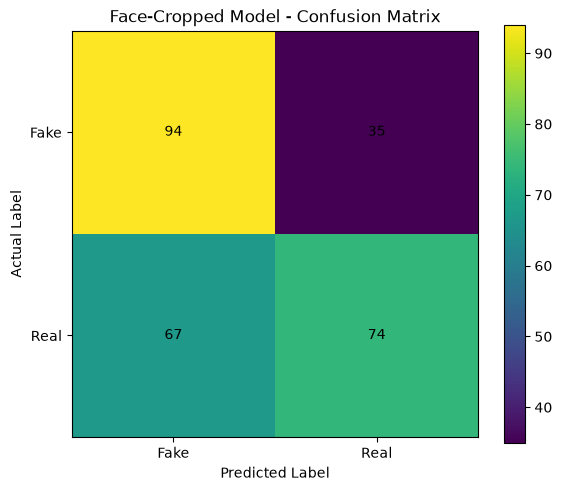

In [16]:
# ============================================
# Cell 16: Confusion Matrix
# ============================================

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Face-Cropped Model - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    [0, 1],
    ["Fake", "Real"]
)

plt.yticks(
    [0, 1],
    ["Fake", "Real"]
)

# Add values inside cells
for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.tight_layout()

plt.show()